In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
source_file = Path(
    "/home/csb/Saloni/EMT_ID/EMT_ID/Figure_time_or_dose_emt/source_data/"
    "MCF10A_dose_ID_scores.csv"
)

data = pd.read_csv(source_file)

if not {"Dose_pM", "ID"}.issubset(data.columns):
    raise ValueError("CSV must contain 'Dose_pM' and 'ID' columns")

data["Dose_pM"] = pd.to_numeric(data["Dose_pM"])
data["ID"] = pd.to_numeric(data["ID"])

doses = sorted(data["Dose_pM"].unique())

id_groups = [
    data.loc[data["Dose_pM"] == dose, "ID"].dropna().to_numpy()
    for dose in doses
]

id_means = [np.mean(group) for group in id_groups]
cell_counts = data["Dose_pM"].value_counts()

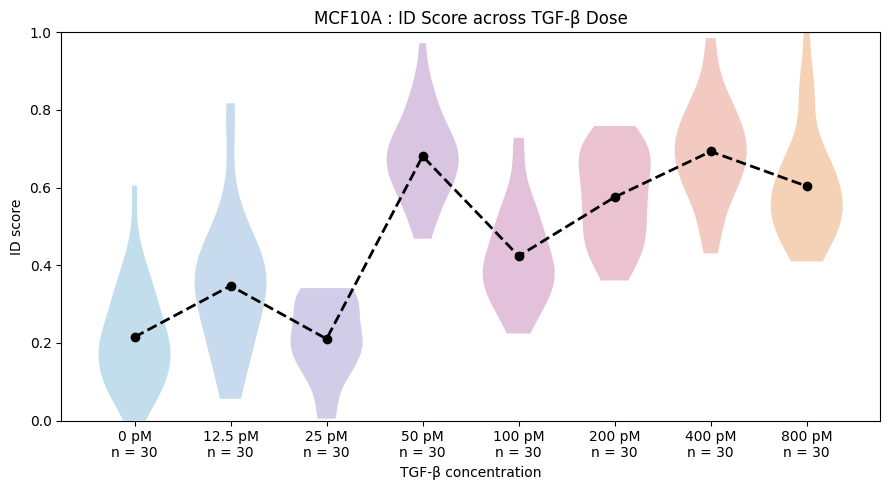

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(doses))

pastel_colors = [
    "#B8D8E8", "#BFD4EA", "#C9C4E4", "#D3BBDD",
    "#DEB6D5", "#E8B8C8", "#F0C1B8", "#F4C9A8"
]

parts = ax.violinplot(
    id_groups,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

for body, color in zip(parts["bodies"], pastel_colors):
    body.set_facecolor(color)
    body.set_alpha(0.85)

ax.plot(
    positions,
    id_means,
    linestyle="--",
    marker="o",
    linewidth=2,
    markersize=6,
    color="black"
)

ax.set_xticks(positions)
ax.set_xticklabels([
    f"{dose:g} pM\nn = {cell_counts.loc[dose]}"
    for dose in doses
])

ax.set_xlabel("TGF-β concentration")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)
ax.set_title("MCF10A : ID Score across TGF-β Dose")

plt.tight_layout()
plt.show()

In [4]:
tukey = pairwise_tukeyhsd(
    endog=data["ID"],
    groups=data["Dose_pM"],
    alpha=0.05
)

tukey_df = pd.DataFrame(
    tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

tukey_df["group1"] = pd.to_numeric(tukey_df["group1"])
tukey_df["group2"] = pd.to_numeric(tukey_df["group2"])
tukey_df["p-adj"] = pd.to_numeric(tukey_df["p-adj"])

tukey_matrix = pd.DataFrame(
    np.nan,
    index=doses,
    columns=doses
)

for _, row in tukey_df.iterrows():
    tukey_matrix.loc[row["group1"], row["group2"]] = row["p-adj"]
    tukey_matrix.loc[row["group2"], row["group1"]] = row["p-adj"]

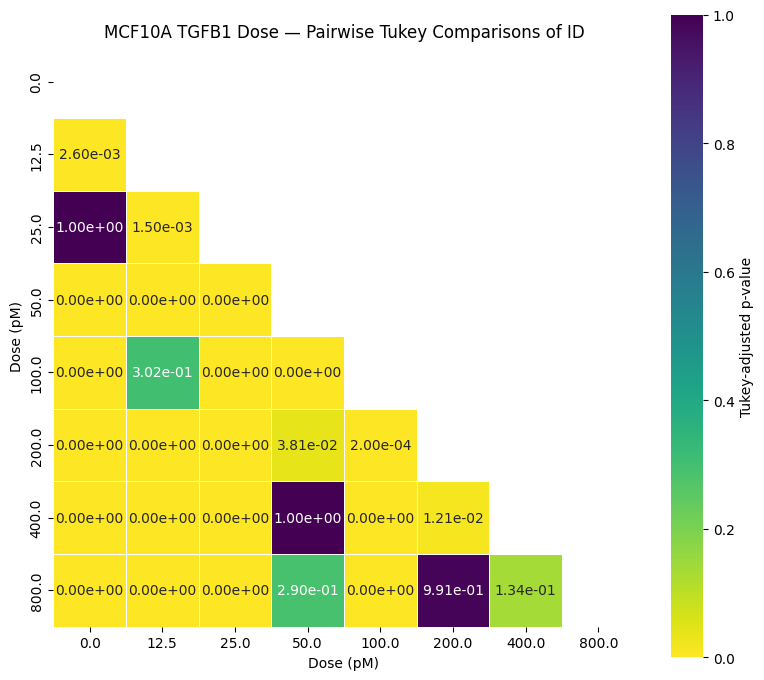

In [5]:
mask = np.triu(
    np.ones_like(tukey_matrix, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    tukey_matrix,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Tukey-adjusted p-value"}
)

plt.title("MCF10A TGFB1 Dose — Pairwise Tukey Comparisons of ID")
plt.xlabel("Dose (pM)")
plt.ylabel("Dose (pM)")
plt.tight_layout()
plt.show()